# Hermes Agent 入门：从项目概念到安装与模型配置


## 从“组装 Agent”到“使用一个现成 Agent”

前面的 LangChain、LangGraph 笔记侧重用代码连接模型、工具、状态与记忆。Hermes Agent 则把这些能力组织成一个可以直接使用、配置和扩展的 Agent 应用。

本章先解决三个问题：Hermes Agent 是什么，怎样选择安装方式，怎样接入模型并管理配置。工具、记忆、Skills、多 Agent 协作等功能将在后续章节展开。

本篇依据《01-入门篇.md》与课程 README 整理。课件标注以 **v0.16.0** 为基准；官方在线文档持续更新，安装器、依赖和界面可能已经变化，具体操作要对照所安装版本。

所有单元格均为 Markdown。安装命令、配置和操作示例都放在带语言标识的代码段中，笔记整理过程中没有执行这些命令。


## Nous Research：先了解项目来自哪里

Nous Research 是 Hermes Agent 的开发团队，也参与开放模型、分布式训练与相关基础设施研究。课件用开源、可定制和服务用户意图来概括其方向。

公司背景、融资和团队介绍有助于认识生态，但不能代替对具体软件能力的验证。入门时更有用的是区分各产品的职责。

| 名称 | 在课件中的定位 | 与本章的关系 |
| --- | --- | --- |
| Hermes 模型系列 | 大语言模型及后训练成果 | 可供理解模型生态，与 Agent 应用是不同层 |
| DeepHermes、NousCoder | 推理或代码方向的模型 | 模型能力取决于具体版本 |
| DisTrO / DeMo | 分布式训练与通信优化相关技术 | 背景知识，不是启动 Agent 的必装组件 |
| Psyche Network | 协调分布式训练算力的网络 | 背景知识，不需要先参与网络才能使用 Agent |
| Forge Reasoning API | 云端推理服务 | 与本地 Agent 的运行程序分开理解 |
| Nous Chat | Web 聊天入口 | 面向聊天体验 |
| Hermes Agent | 带工具、记忆、技能等能力的 Agent 应用 | 本系列学习对象 |
| Hermes Desktop | 图形化桌面入口 | 本章的使用方式之一 |

课件中星标数、融资金额、性能倍率和拒绝率属于特定统计口径。选择工具时优先检查任务效果、可维护性、成本与实际支持的平台。


## Hermes 模型、Hermes Agent、Hermes Desktop，不要混为一层

| 层 | 主要职责 | 一个例子 |
| --- | --- | --- |
| 模型 | 理解输入、生成输出、决定工具调用 | 某个 Hermes、Claude、DeepSeek 等模型 |
| Agent 运行程序 | 组织消息、执行工具、管理会话和经验 | Hermes Agent |
| 交互入口 | 接收任务、展示过程与结果 | CLI、TUI、Desktop、消息平台 |

~~~text
用户 → Desktop / 终端 / 消息入口 → Hermes Agent
                                 ├─ Provider → 对话模型
                                 ├─ 工具 → 文件、终端、网页等
                                 └─ 会话、记忆、Skills → 可复用上下文与经验
~~~

**安装 Hermes Agent 不等于下载并在本机运行一个大模型。**使用远程 Provider 时，模型推理在服务端完成，本机主要运行 Agent 与工具；使用本地模型服务时，才需要另外准备对应模型和推理环境。

因此，Hermes Agent 可以接入多个模型厂商，并不要求必须使用 Hermes 系列模型。服务端模型、Agent 程序和用户界面也可以运行在不同机器上。


## “自进化”具体发生在哪里？

课件强调内置学习循环，可以理解为把任务经验保存下来，并在后续任务中使用和维护。

~~~text
解决任务 → 提炼可复用流程 → 保存 Skill
       → 后续任务读取和调整 → 维护、合并或归档经验
~~~

| 能力 | 保存或处理什么 | 需要分清的边界 |
| --- | --- | --- |
| Skills | 人类可读的操作流程与说明 | 保存流程不等于修改底层模型权重 |
| 持久记忆 | 用户偏好、长期事实与重要约定 | 保存什么、何时更新，需要检查规则 |
| 历史会话检索 | 从以往对话恢复相关上下文 | 搜索历史不等于把全部历史永远塞入提示词 |
| Curator | 维护 Agent 创建的技能条目 | 自动整理也可能出错，需要可检查的记录 |

这里的“学习”主要通过外部文件、存储和上下文影响行为。它不是每做一个任务就在本机自动微调一个大模型，也不能承诺使用次数越多，所有任务表现就必然提升。

第 02 篇会展开工具与记忆，第 03 篇再学习 Skills、Curator、Hooks 和 Plugins 的具体机制。


## 其他能力先认识名字，后面逐项展开

| 能力 | 解决的问题 | 后续章节 |
| --- | --- | --- |
| Toolsets / MCP | Agent 怎样使用外部工具和服务 | 02 能力篇 |
| 上下文文件、会话与 Dashboard | 怎样管理当前任务、历史与观察界面 | 02 能力篇 |
| Hooks / Plugins / Cron | 怎样扩展生命周期与定时工作 | 03 进化篇 |
| Gateway | 从消息平台与远程入口访问 Agent | 04 协作篇 |
| Profile | 分开配置、技能、记忆与会话 | 04 协作篇 |
| Delegation / Kanban | 委派任务并组织多个 Agent 的工作 | 04 协作篇 |

能够接入工具，不代表相应工具的账号、依赖和访问权限已经配置好。模型会发出工具调用请求，Agent 再依据工具配置执行并把结果交回模型。

课件也与 OpenClaw 做了对照。评估同类产品时可以比较技能格式、记忆管理、模型接入、操作系统支持、界面与迁移成本；这些能力随版本变化。不能只凭“某产品技能不透明”“某产品没有桌面版”等概括就做长期结论。


## 先选环境：Windows 原生与 WSL 是两套运行位置

| 环境 | 本章的选择方式 | 默认数据位置 |
| --- | --- | --- |
| Linux / macOS | POSIX 安装脚本，或平台支持的桌面包 | `~/.hermes/` |
| Windows 原生 | PowerShell 安装脚本，或 Windows 桌面包 | `%LOCALAPPDATA%\hermes\` |
| Windows + WSL2 | 在 WSL 的 Linux 终端使用 POSIX 脚本 | WSL 内的 `~/.hermes/` |
| Android / Termux | 参照 Termux 专用安装文档 | 依安装方式确定 |

课件写 Python 3.11+、Git 等前置条件。当前官方安装流程会准备受管理的运行时和依赖，支持版本要按当前安装文档核对，不能只按“系统 Python 能运行”判断。

原生 Windows 与 WSL 不会因为运行在同一台电脑上，就自动共享配置、密钥和会话。先确定本次使用哪一个环境，再查对应的数据目录。

本地模型的硬件需求取决于所选模型；使用远程模型仍需要网络、账号和工具运行环境。课件中的低价 VPS 示例不是所有任务的资源保证。


## Windows：从 PowerShell 安装

课件的原生 Windows 安装命令是：

~~~powershell
iex (irm https://hermes-agent.nousresearch.com/install.ps1)
~~~

irm 是 Invoke-RestMethod 的别名，用于获取脚本；iex 是 Invoke-Expression 的别名，用于执行取得的脚本。这是一条下载安装并执行的命令，不是只下载文件。

默认源码目录为 `%LOCALAPPDATA%\hermes\hermes-agent\`，命令入口位于 `%LOCALAPPDATA%\hermes\bin\`，用户数据目录为 `%LOCALAPPDATA%\hermes\`。具体布局以所用安装器说明为准。

安装流程可以准备所需 Git / Git Bash 等组件，原生路线无需先装 WSL。安装完成后重新打开 PowerShell，再检查命令是否可找到。

~~~powershell
Get-Command hermes
hermes --version
hermes doctor
~~~

找到命令、识别版本、通过环境诊断是三个不同检查。doctor 也不代表实际模型调用、每个工具和所有任务都已经验证成功。


## Linux / macOS / WSL2：在对应终端安装

~~~bash
curl -fsSL https://hermes-agent.nousresearch.com/install.sh | bash
~~~

curl 获取脚本，管道把内容交给 bash 执行。课件的安装流程会获取源码、建立运行环境、准备依赖、生成命令入口，并初始化配置。

常见源码位置为 `~/.hermes/hermes-agent/`，用户数据在 `~/.hermes/`，启动包装器通常在 `~/.local/bin/`。修改 PATH 后重新打开终端，或重新加载相应 shell 配置。

~~~bash
command -v hermes
hermes --version
hermes doctor
~~~

在 WSL 内执行这些命令，使用的是 WSL 的 Linux 环境。不要把 Windows 的 LOCALAPPDATA 路径直接当成 WSL 默认数据位置。

### Termux 补充

课件也给 Termux 列出了同一条脚本。当前官方文档已提供 aarch64 Android 的签名 APT 包路线，需要先配置指定软件源，再安装 hermes-agent。复现时参照 [Termux 专用说明](https://hermes-agent.nousresearch.com/docs/getting-started/termux)，不要无条件套用桌面 / 服务器安装脚本。


## 安装器做了什么，首次配置还要做什么？

| 阶段 | 主要工作 | 完成后仍需确认 |
| --- | --- | --- |
| 准备程序 | 获取源码或安装桌面包 | 来源、版本、安装方式 |
| 准备运行环境 | Python、依赖与部分工具组件 | 是否有失败步骤或缺少系统库 |
| 创建入口 | 建立 hermes 启动命令 | PATH 与当前终端是否识别 |
| 初始化数据 | 准备配置文件和目录 | 当前实际的数据根目录 |
| 设置向导 | 选择 Provider、模型及所需功能 | 凭证、额度、网络与具体工具 |

已有配置通常由安装器保留或迁移。遇到问题先查看安装日志和 doctor 输出，不应把“删除整个数据目录”当作普通的重装步骤。

源码安装和完整 Desktop 包的依赖准备方式不同；当前完整桌面包会包含基础运行环境，源码构建则可能还需编译依赖。不要把一种方式的故障处理直接套到另一种方式。


## 第一次接入模型：model、setup 与 Portal

下面是三个入口，按目的选择，不需要为第一次配置连续重复运行全部命令。

~~~bash
hermes model
hermes setup
hermes setup --portal
~~~

| 命令 | 用途 |
| --- | --- |
| hermes model | 选择或重新配置模型 Provider 与模型 |
| hermes setup | 运行较完整的设置向导 |
| hermes setup --portal | 通过 Nous Portal 的 OAuth 入口配置相关服务 |

使用 API Key 的提供商，需要填写正确密钥和相应模型；OAuth 路线通过账号授权获得凭证。Portal 减少逐个管理密钥的步骤，但能使用哪些模型和工具，仍取决于账号、订阅与服务权限。

API Key 与 OAuth 令牌不是同一种配置。前者通常保存在数据目录的 .env，后者通常由 auth.json 等认证数据管理。使用本地模型服务，也要确认服务已启动并支持所需接口。


## Provider、模型名、地址与凭证，各管什么？

| 配置 | 回答的问题 | 例子 |
| --- | --- | --- |
| Provider | 通过哪一种接入方式调用 | 某厂商、聚合网关、本地服务 |
| Model | 调用该渠道中的哪一个模型 | 渠道实际提供的模型 ID |
| Base URL | 请求发送到哪里 | 服务商给出的 API 地址 |
| Credential | 用什么身份获得服务权限 | API Key、OAuth、IAM 等 |

模型显示名和真实 API model ID 可能不同；同名模型在不同渠道也可能有不同的能力和价格。切换模型时，要检查渠道支持和账号权限。

**OpenAI 兼容**通常表示实现部分相似的请求协议，不保证所有工具调用、流式事件、图像输入、推理参数或认证方式都完全兼容。接入后还要验证自己使用的功能。

Provider 是服务渠道，不是“在本机装了几百个模型”。选择远程模型时，Agent 会向该服务发送本次请求所需内容。


## 课件中的常见 Provider，按接入方式理解

| 提供商 / 渠道 | 课件列出的主要接入方式 | 配置时关注 |
| --- | --- | --- |
| Nous Portal | OAuth | 登录授权、订阅及可用模型 |
| Anthropic | API Key 或对应授权路线 | 安装版本支持的认证方式、模型能力 |
| OpenAI | API Key 或相应接口路线 | 模型 ID、API 能力和额度 |
| OpenRouter | API Key | 聚合渠道的模型名、路由与计费 |
| AWS Bedrock | IAM 等 AWS 认证 | 区域、模型访问权限与账户配置 |
| Google Gemini | 账号授权或相应 Provider 配置 | 支持的认证路线与可用模型 |
| xAI / Grok | API Key 或对应授权路线 | 模型与扩展服务是否可用 |
| DeepSeek | API Key | 模型名、地址与余额 |
| GitHub Copilot | OAuth | 账号权限与实际可用模型 |
| Hugging Face / NVIDIA NIM | 对应服务凭证或端点 | 托管模型、端点和推理限制 |
| LM Studio | 本地服务 | 模型加载、端口、工具调用支持 |
| MiniMax、Kimi、GLM 等 | 对应渠道配置 | 版本支持、认证与计费 |
| 自定义端点 | 兼容 API 地址及其认证 | 协议与 Agent 功能是否兼容 |

Provider 清单会随版本增减。课件中的“20+ 提供商、400+ 模型”等数量是版本与服务口径，不能当作固定配置值；上下文长度也由具体模型和渠道决定，不是整个 Provider 都具有同一个上限。

入门时先配置一条稳定、可用的渠道，完成简单问答后再比较速度、价格、工具调用和中文效果。


## Desktop：在图形界面配置默认模型

Hermes Desktop 提供对话、模型配置、文件输入、命令面板等入口。按 [Desktop 安装说明](https://hermes-agent.nousresearch.com/docs/getting-started/desktop) 获取对应平台的包，并依据所用版本完成首次配置。

课件截图显示“模型”设置页和 Provider 下拉框。先选择提供商，再通过该渠道配置可用模型与认证。界面提示这里的选择应用于新会话，当前会话还可以从输入框旁的模型选择器临时切换。

来源截图中的厂商和模型名称只是教学界面的当时状态，自己的列表可能不同。截图里出现模型名，也不代表当前账号已经取得调用权限。

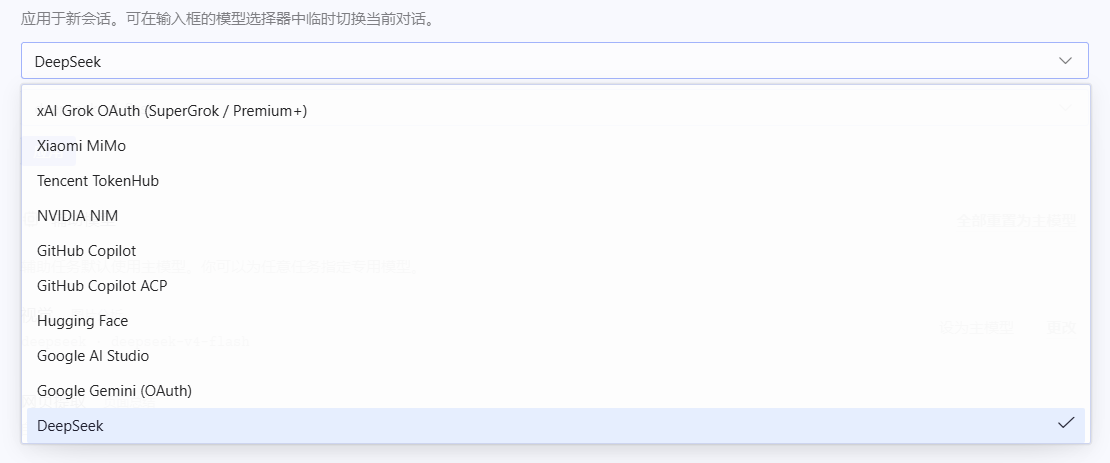

课件截图局部：模型设置页中选择 Provider；默认配置与当前会话切换要分清。


## Desktop：当前会话切换模型，配置何时生效？

输入框附近的模型菜单用于选择当前会话的模型，课件也展示了搜索框和“编辑模型”入口。修改后可先发一个简短问题，确认实际使用的模型与服务状态。

| 操作 | 用途与范围 |
| --- | --- |
| 默认模型设置 | 为后续新会话选择默认值，具体行为看当前界面提示 |
| 当前会话模型菜单 | 调整本次会话使用的模型 |
| 多标签页对话 | 分开多个任务的会话上下文 |
| 命令面板 | 搜索界面中可用的操作 |
| 文件拖放 / 图片粘贴 | 把资料加入当前任务，是否能理解图片取决于模型和解析能力 |
| Remote Gateway | 连接另一台机器上的 Hermes 后端 |

本地 Desktop 与 CLI 使用同一个数据根目录时，可以共享对应配置和数据。连接远程 Gateway 时，运行环境与数据位置由远端决定，不能认为所有本地和远端会话都会自动同步。

界面入口不同，后台仍需要可用的模型、工具和相应权限。

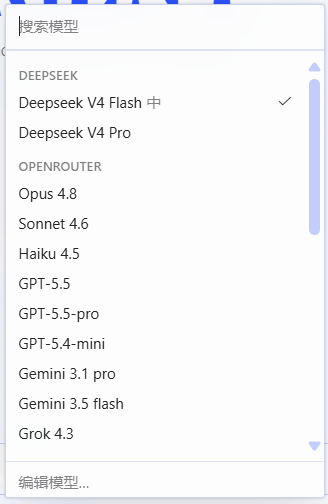

课件截图局部：当前会话的模型选择器，可搜索并切换渠道中可用的模型。


## 终端交互：普通入口与 TUI

~~~bash
hermes
hermes --tui
~~~

hermes 启动交互式会话，具体默认界面由所用版本与配置决定；--tui 显式选择终端界面。TUI 常提供固定输入栏、流式输出和任务观察等能力，界面细节会随版本调整。

这两个入口是可选使用方式，不是在同一次会话中顺序运行两次。选择一个入口后，用自然语言给任务，再查看工具调用、结果与必要的确认。

~~~text
请先说明你准备怎样检查当前目录。
只读取文件列表，概括项目结构，不修改文件。
~~~

第一次使用宜选范围清楚的任务。Agent 接收到自然语言约束后仍要看实际执行记录，不能只根据它说“已完成”就认定文件与结果都正确。


## 单次调用：适合脚本与一次性问题

~~~bash
hermes chat -q "查看系统资源占用情况"
~~~

chat -q 把任务直接传给 Agent，不进入持续的交互输入循环。它仍可能调用模型和工具，并不是只输出一条预设文本。

查询系统资源时，Agent 实际在哪台机器运行，查到的通常就是哪台机器的资源；通过远程 Gateway 交互时，要确认后端运行位置。

第一次也可以先用一个不需要工具的简单问答，检查模型接入，再逐步测试文件、终端或网页等工具。模型认证可用与工具配置可用要分别验证。


## 快捷键：区分 Desktop、终端与操作系统

| 场景 | 快捷键 | 课件说明与使用边界 |
| --- | --- | --- |
| Desktop | Cmd / Ctrl + K | 打开命令面板，按平台与界面提示使用 |
| Desktop | Ctrl + V 等粘贴操作 | 可粘贴图片，实际内容取决于剪贴板与模型支持 |
| 终端 | Alt + V | 课件中的图像粘贴方式，受终端支持影响 |
| 终端 | Ctrl + C | 中断当前操作，具体响应由任务和界面决定 |
| 终端 | Ctrl + D | 常用于退出或发送 EOF，不同输入状态可能不同 |
| 终端 | Alt + Enter / Ctrl + J | 课件中的多行输入方式 |
| 终端 | Shift + Enter | 终端需要能区分并传送相应按键序列 |
| POSIX 终端 | Ctrl + Z，随后 fg | 暂停和恢复前台进程，依赖 shell 作业控制 |

Ctrl + Z / fg 不是原生 Windows PowerShell 的通用暂停恢复方案。多行输入和图片粘贴遇到差异时，先查当前界面与终端的按键说明。


## 配置在哪：源码目录与数据目录分别查

| 位置 | 默认用途 |
| --- | --- |
| `~/.hermes/hermes-agent/` | POSIX 源码安装的程序目录 |
| `~/.hermes/` | POSIX 用户配置与数据 |
| `%LOCALAPPDATA%\hermes\hermes-agent\` | Windows 源码安装的程序目录 |
| `%LOCALAPPDATA%\hermes\` | Windows 原生用户配置与数据 |
| HERMES_HOME 指定目录 | 显式选择的数据根目录 |

源码安装中两类目录可能彼此包含，但职责不同。源码更新与数据迁移分别处理；修复程序文件不应误删记忆、会话与凭证。

下面是 Windows 默认 / HERMES_HOME 路线的路径检查示例：

~~~powershell
$hermesDataRoot = if ($env:HERMES_HOME) {
    [Environment]::ExpandEnvironmentVariables($env:HERMES_HOME)
} else {
    Join-Path $env:LOCALAPPDATA 'hermes'
}
Get-Item -LiteralPath $hermesDataRoot
Get-Item -LiteralPath (Join-Path $hermesDataRoot 'config.yaml')
~~~

如果使用了 Profile、启动器中的单独配置或远程后端，应以该实例的实际路径为准。第 04 篇再展开多实例隔离。


## 数据目录里的文件，各自保存什么？

课件给出的结构可以作为定位入口；实际版本可能增加数据库、缓存和其他文件。

~~~text
Hermes 数据目录/
├─ config.yaml      # 非机密运行设置
├─ .env             # API Key、令牌等环境配置
├─ auth.json        # OAuth 认证数据
├─ SOUL.md          # 主 Agent 的身份、风格与行为说明
├─ memories/        # 持久记忆，如 MEMORY.md、USER.md
├─ skills/          # 技能说明及相关资源
├─ cron/            # 定时任务数据
├─ sessions/        # 部分会话相关数据
└─ logs/            # 运行与诊断日志
~~~

| 文件 | 适合放什么 | 不要混淆 |
| --- | --- | --- |
| config.yaml | 模型选择、工具设置、终端后端等 | YAML 设置不是 API Key 清单 |
| .env | 对应 Provider / 工具的密钥和环境变量 | 文件内容不会因改了界面显示就自动成为有效权限 |
| auth.json | OAuth 登录与令牌信息 | 凭证不是聊天记录 |
| SOUL.md | Agent 身份、风格和行为说明 | 不能代替实际工具权限与业务授权 |

会话的存储方式可能包含数据库，不能只备份 sessions 目录就假定保留了全部历史。日志提供脱敏机制，分享日志前仍需核对其中的任务内容、路径与认证信息。


## 配置管理：先看配置，再改明确的项

课件给出三个基本入口：

~~~bash
hermes config
hermes config edit
hermes config set section.key value
~~~

最后一行是语法模板，section.key 和 value 要换成真实项和值，不应照字面输入。config edit 用已配置的编辑器打开配置文件；编辑器的选择与系统环境有关。

下面是当前官方文档中的查询与修改示例，旧版本使用前先查看帮助：

~~~bash
hermes config --help
hermes config get model
hermes config set terminal.backend docker
hermes config get terminal.backend
~~~

terminal.backend 表示终端工具使用的执行后端，设置 docker 还需要可用的 Docker 环境。这个例子用于理解点分配置路径，不是完成普通聊天的必做步骤。

命令成功写入一个值，也不代表该版本一定识别拼写错误的配置项。修改后要检查配置回读、诊断结果与实际行为。


## config.yaml 与 .env：一个结构示例

下面补充一个最小的模型配置形状，便于理解两个文件的职责。先用 hermes model 生成实际配置，再对照阅读；不要用占位示例覆盖现有文件。

config.yaml 中放非机密设置：

~~~yaml
model:
  provider: "openrouter"
  default: "填写该渠道实际可用的模型ID"
~~~

.env 中放对应密钥：

~~~dotenv
OPENROUTER_API_KEY=your_api_key_here
~~~

模型 ID 与密钥均需替换为自己渠道实际支持的值。自定义服务还可能需要 model.base_url 等地址设置，不同 Provider 的配置字段与认证路线要按版本核对。

YAML 使用空格缩进，层级和字段名要正确；.env 是环境变量赋值格式，不能把两者混着写。真实密钥与 auth.json 不应放入公开笔记、截图或代码仓库。


## 会话内命令：调整当前交互的状态

这些斜杠命令在 Hermes 的会话输入框中使用，不是直接交给 PowerShell / Bash 执行的 shell 命令。

~~~text
/config
/model
/personality
/reasoning
/voice
/yolo
~~~

| 命令 | 课件中的作用 | 注意范围 |
| --- | --- | --- |
| /config | 查看配置 | 支持内容依安装版本 |
| /model [model-name] | 查看或切换会话模型 | 切换不代表更改所有实例的默认值 |
| /personality [name] | 选择预设交互风格 | 风格不能改变工具的实际权限 |
| /reasoning [level/show/hide] | 调整或显示推理相关设置 | 模型与渠道不一定支持同样选项 |
| /voice [on/off/tts/status] | 语音输入、输出与状态 | 需要对应服务或设备支持 |
| /yolo | 切换执行确认相关模式 | 影响确认流程，不能等同于授予操作系统权限 |

方括号表示参数位置，不是命令中必须输入的字符。入门时先学习 /config 与 /model，确认模型和会话状态，再按需要学习其他选项。


## 修改了设置却没生效，先看配置来自哪里

当前官方文档对普通非机密设置给出的优先级概括是：

~~~text
本次调用的命令行覆盖 → config.yaml → .env 中的后备设置 → 内置默认值
~~~

API Key、OAuth、管理员托管设置和个别运行参数有各自的读取规则，不能把这个顺序机械套到所有字段。进程已经启动时，修改磁盘文件也不保证立即刷新当前会话。

遇到差异可以依次检查：

1. 当前是 Windows 原生、WSL、本地 Desktop，还是远程 Gateway？
2. 使用哪个数据目录和 Profile，是否设置了 HERMES_HOME？
3. 命令行或当前会话是否临时覆盖了默认值？
4. Provider、模型 ID、凭证是否属于同一条接入渠道？
5. 配置格式与字段名是否正确，当前进程是否需要重新载入？

这比反复重跑完整 setup 更容易找到原因，也能减少意外覆盖其他设置。


## 按一条最小路线检查首次使用

下面展示已经完成安装后的操作路线，命令在笔记中没有执行。

~~~bash
hermes --version
hermes doctor
hermes model
hermes chat -q "用一句话说明大语言模型和Agent的区别。"
~~~

| 检查点 | 预期观察 | 仍不能说明什么 |
| --- | --- | --- |
| 命令与版本 | hermes 能启动，版本明确 | 不代表模型账号可用 |
| doctor | 能定位环境和部分配置问题 | 不代表每个工具已验证 |
| model 向导 | 完成渠道、模型与凭证配置 | 不代表所有模型都可调用 |
| 简短问答 | 返回实际模型输出 | 不代表终端、浏览器等工具都可用 |
| 一个受限读取任务 | 工具过程与结果符合任务范围 | 不代表任意复杂任务都可靠 |

查看任务过程时，分别检查模型响应、工具执行与最终结果。若工具失败，应该能看到错误或缺失条件，而不是只得到一段看起来完整的回答。


## 更新：先确认安装方式和数据保留

课件中的更新命令是：

~~~bash
hermes update
~~~

源码安装通常沿对应更新路线升级程序与依赖。Desktop 包、商店包、Docker 和 Termux 等安装方式可能有各自的更新归属，不应统一按源码 checkout 处理。

更新前记下当前版本与数据位置，备份配置和重要数据；更新后再检查版本、doctor、模型调用与常用工具。主要版本变化还需要核对配置迁移和功能变更说明。

原资料重点提醒备份 auth.json 和 config.yaml；如果要恢复完整使用状态，还要考虑 .env、技能、记忆、任务和会话数据，而不只是两个文件。


## 备份：配置备份与完整备份不是一回事

下面是 Windows 的简化配置备份示例，沿用前面的 hermesDataRoot 变量。它复制三个配置 / 认证文件，不执行卸载或删除。

~~~powershell
$hermesBackupDir = Join-Path $env:USERPROFILE (
    'hermes-config-backup-' + (Get-Date -Format 'yyyyMMdd-HHmmss')
)
New-Item -ItemType Directory -Path $hermesBackupDir | Out-Null

foreach ($hermesFileName in @('config.yaml', '.env', 'auth.json')) {
    $hermesConfigFile = Join-Path $hermesDataRoot $hermesFileName
    if (Test-Path -LiteralPath $hermesConfigFile -PathType Leaf) {
        Copy-Item -LiteralPath $hermesConfigFile -Destination $hermesBackupDir
    }
}
Get-ChildItem -LiteralPath $hermesBackupDir -Force
~~~

这个目录含有认证数据，应妥善保管。源文件不存在时会跳过，不能只看到备份目录创建成功，就认定登录状态和全部数据已保存。

完整迁移还需要技能、记忆、任务、会话数据库与相关资源。正式备份应使用对应版本的备份 / 导入方案，并验证恢复；运行中的数据库也不宜随意当普通静态文件复制。


## 卸载程序与清除个人数据，影响不同

课件列出的入口为：

~~~bash
hermes uninstall
~~~

实际卸载范围要看版本、提示与安装方式。商店或完整 Desktop 包一般还应遵循所属包管理方式；源码安装的卸载命令不能代替每一种包的卸载流程。

删除整个 Hermes 数据根目录会影响配置、密钥、记忆、技能、会话和任务。源码安装中，该目录还可能包含程序本身，所以“清掉数据”与“卸载应用”不能混为一个不影响状态的操作。

需要完整清理时，先确认使用的是哪个实例、实际目录和备份，再按该版本的卸载说明处理。课件的递归删除示例在本笔记中不作为日常修复步骤。


## 常见故障，按发生的层排查

| 现象 | 先检查 | 下一步 |
| --- | --- | --- |
| hermes 命令找不到 | PATH、当前终端、安装入口 | 重新打开终端，定位实际命令目录 |
| 安装脚本失败 | 网络、依赖下载、安装日志 | 根据失败阶段修复，不先删除个人数据 |
| API Key / OAuth 报错 | 认证路线、实际数据目录、账号权限 | 用 model 向导检查对应渠道 |
| 模型不存在或无权访问 | 模型 ID、Provider 与服务额度 | 从当前渠道可用列表重新选择 |
| 能聊天，工具不能工作 | 工具账号、工具集、依赖与执行后端 | 分别验证工具配置与环境 |
| Docker 后端不可用 | Docker 是否运行、权限与后端设置 | 修复后端，或选择适合的执行方式 |
| Desktop 和 CLI 状态不同 | HERMES_HOME、Profile、远端连接 | 查两者是否使用同一后端与数据 |
| 设定不生效 | 字段名、YAML、覆盖关系、重载 | 查看回读值并检查实际行为 |
| 快捷键不一致 | 当前界面、终端与平台 | 使用该界面的帮助与按键提示 |

先用 hermes doctor 收集环境线索，再围绕具体错误定位。安装成功、模型可用、工具可用和任务完成，是逐层建立的事实。


## 本章回顾与复习问答

本章建立一条完整入门路线：认识 Hermes Agent → 选择环境和安装方式 → 接入 Provider 与模型 → 完成一次简单对话 → 找到配置和数据 → 学会诊断、更新与备份。

| 问题 | 回答要点 |
| --- | --- |
| Hermes Agent 是一个模型吗？ | 它是运行 Agent 的应用，可调用多个渠道中的模型 |
| 自进化是否表示自动微调模型？ | 本章主要指积累、使用和维护外部技能与记忆 |
| Windows 原生与 WSL 自动共享配置吗？ | 不会，默认目录与运行环境不同 |
| Provider 和模型名有什么区别？ | Provider 是接入渠道，模型名指定该渠道中的模型 |
| config.yaml、.env、auth.json 分别做什么？ | 普通设置、环境配置 / 密钥、OAuth 认证数据 |
| hermes model 与 /model 分别在哪里用？ | 前者在 shell 中管理模型接入，后者在会话中使用 |
| 模型能回答，是否代表所有工具都能运行？ | 不代表，工具依赖、账号与权限要分别验证 |
| Desktop 与 CLI 何时能共享状态？ | 使用相同后端和数据根目录时，对应数据可共享 |
| 删除数据目录是否只是重装应用？ | 会影响个人数据和凭证，且可能包含源码程序 |

下一章进入会话管理、Dashboard、Toolsets、MCP、上下文文件与持久记忆，进一步理解 Agent 怎样连接工具并持续工作。


## 资料来源与版本边界

主资料：[原始课件包](<D:/baidudisk/BaiduNetdiskDownload/1、课件(1)/1.课件.rar>) 中的《01-入门篇.md》和 README，课件标注基准版本为 v0.16.0。两张 Desktop 图片来自包内 images，按相关操作区域裁剪并作为 notebook 附件保存。

- [Hermes Agent GitHub](https://github.com/NousResearch/hermes-agent)
- [官方安装说明](https://hermes-agent.nousresearch.com/docs/getting-started/installation)
- [Desktop 说明](https://hermes-agent.nousresearch.com/docs/getting-started/desktop)
- [配置管理](https://hermes-agent.nousresearch.com/docs/user-guide/configuration)
- [模型提供商](https://hermes-agent.nousresearch.com/docs/integrations/providers)
- [Termux 安装](https://hermes-agent.nousresearch.com/docs/getting-started/termux)

整理时对照了当前官方安装、配置文档和公开 CLI / 配置源码，以说明目录、配置字段和新版安装路线。当前资料的核对不等于对课件基准版本进行了安装测试。

本篇完成的是阅读笔记与静态格式检查，没有安装 Hermes、调用模型、修改系统配置，或执行备份、更新、卸载示例。
